# 01 - Exploratory Data Analysis (EDA)

**Kompetisi:** Structural Damage Classification (gempa Gorkha, Nepal 2015)
**Tujuan:** memahami data sebelum modeling - kualitas data, distribusi target, outlier, dan hubungan fitur dengan `damage_grade`.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Root repo = satu level di atas folder notebooks/
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.append(str(ROOT))

from scripts.preprocess import load_data, split_xy, TARGET, ID_COL

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

train, test, sample = load_data()
order = [f"Grade {i}" for i in range(1, 6)]

## 1. Gambaran umum data

In [2]:
print("train:", train.shape, "| test:", test.shape)
display(train.head())
print(train.dtypes)
print("\nMissing value  -> train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
print("building_id duplikat di train:", train[ID_COL].duplicated().sum())

train: (533465, 17) | test: (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


building_id               int64
district_id               int64
vdcmun_id                 int64
ward_id                   int64
count_floors_pre_eq       int64
age_building              int64
plinth_area_sq_ft         int64
height_ft_pre_eq          int64
land_surface_condition      str
foundation_type             str
roof_type                   str
ground_floor_type           str
other_floor_type            str
position                    str
plan_configuration          str
damage_grade                str
superstructure              str
dtype: object



Missing value  -> train: 0 | test: 0


building_id duplikat di train: 0


## 1b. Kolom yang tidak dipakai dan baris duplikat

`building_id` hanya identitas sehingga dibuang dari fitur.

In [3]:
dup_exact = train.drop(columns=[ID_COL]).duplicated().sum()
print(f"Baris duplikat (semua kolom selain building_id sama, termasuk label): {dup_exact:,} ({dup_exact / len(train):.2%})")

Baris duplikat (semua kolom selain building_id sama, termasuk label): 22,281 (4.18%)


## 2. Distribusi target (`damage_grade`)

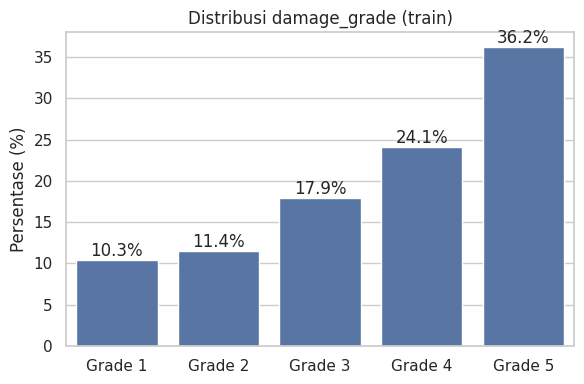

damage_grade
Grade 1     55170
Grade 2     61080
Grade 3     95488
Grade 4    128691
Grade 5    193036
Name: count, dtype: int64


In [ ]:
counts = train[TARGET].value_counts().reindex(order)
pct = counts / len(train) * 100
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=pct.index, y=pct.values, ax=ax, color="#4C72B0")
for i, v in enumerate(pct.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax.set(ylabel="Persentase (%)", xlabel="", title="Distribusi damage_grade (train)")
fig.tight_layout()
fig.savefig(FIG_DIR / "target_distribution.png", dpi=150)
plt.show()
print(counts)

## 3. Fitur numerik dan outlier

,count,mean,std,min,1%,50%,99%,max
count_floors_pre_eq,533465.0,2.1,0.7,1.0,1.0,2.0,4.0,9.0
age_building,533465.0,24.3,65.0,0.0,1.0,16.0,90.0,999.0
plinth_area_sq_ft,533465.0,406.5,226.6,70.0,120.0,358.0,1222.0,5000.0
height_ft_pre_eq,533465.0,16.0,5.5,6.0,6.0,16.0,32.0,99.0


age_building == 999: 0.41% (train), 0.41% (test)


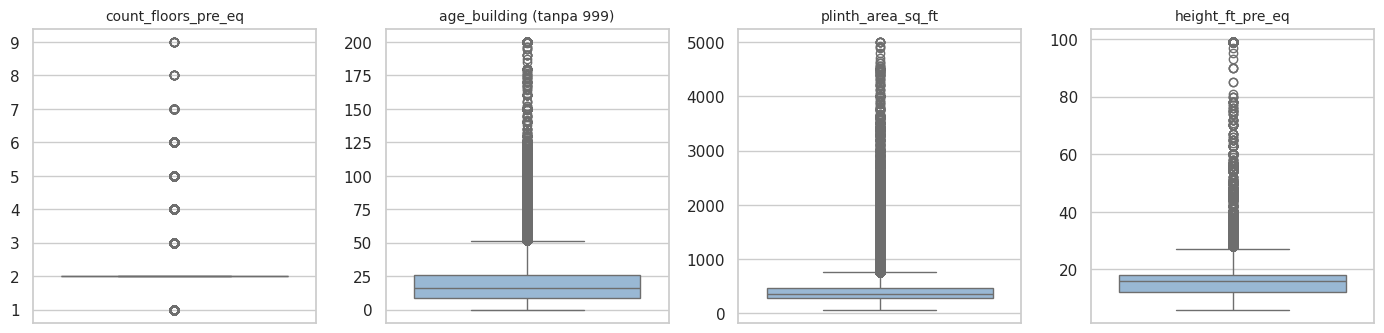

In [5]:
num = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
display(train[num].describe(percentiles=[.01, .5, .99]).T.round(1))
print(f"age_building == 999: {(train.age_building == 999).mean():.2%} (train), {(test.age_building == 999).mean():.2%} (test)")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, c in zip(axes, num):
    data = train[c][train[c] != 999] if c == "age_building" else train[c]
    sns.boxplot(y=data, ax=ax, color="#8FB8DE")
    ax.set_title(c + (" (tanpa 999)" if c == "age_building" else ""), fontsize=10)
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "numeric_outliers.png", dpi=150)
plt.show()

**Catatan:** nilai `age_building = 999` adalah kode "umur tidak diketahui" (bukan umur sebenarnya). Pada pipeline, nilai ini diubah menjadi NaN dan diberi flag `age_unknown` (lihat `scripts/feature_engineering.py`).

**Outlier:** luas (hingga 5.000 sq ft) dan tinggi (hingga 99 ft) berekor panjang. Outlier diredam lewat fitur `log_plinth_area` dan model berbasis pohon yang tahan outlier.

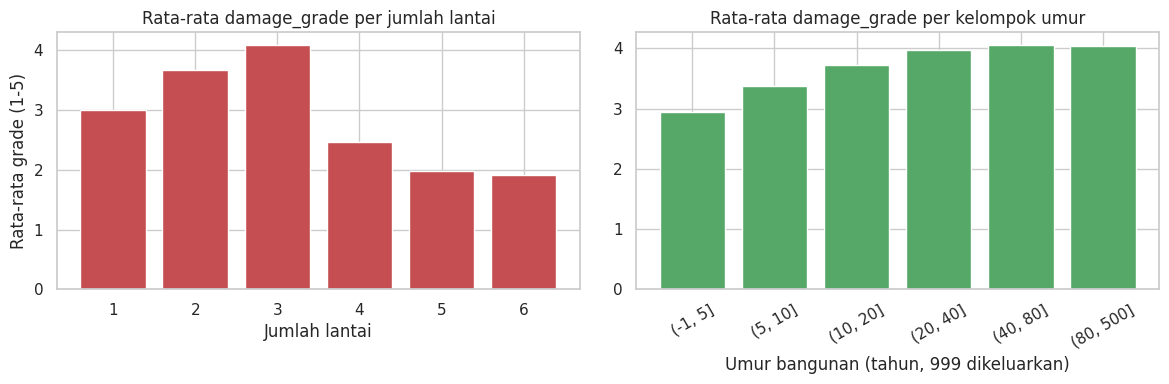

In [6]:
d = train.copy()
d["grade_num"] = d[TARGET].str.extract(r"(\d)")[0].astype(int)
d["age_clean"] = d.age_building.where(d.age_building != 999)
d["age_bin"] = pd.cut(d.age_clean, [-1, 5, 10, 20, 40, 80, 500])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fl = d.groupby("count_floors_pre_eq")["grade_num"].agg(["mean", "size"])
fl = fl[fl["size"] >= 100]
axes[0].bar(fl.index.astype(str), fl["mean"], color="#C44E52")
axes[0].set(title="Rata-rata damage_grade per jumlah lantai", xlabel="Jumlah lantai", ylabel="Rata-rata grade (1-5)")
ag = d.groupby("age_bin", observed=True)["grade_num"].mean()
axes[1].bar(ag.index.astype(str), ag.values, color="#55A868")
axes[1].set(title="Rata-rata damage_grade per kelompok umur", xlabel="Umur bangunan (tahun, 999 dikeluarkan)", ylabel="")
plt.setp(axes[1].get_xticklabels(), rotation=30)
fig.tight_layout()
fig.savefig(FIG_DIR / "damage_by_floors_age.png", dpi=150)
plt.show()

## 4. Fitur kategorikal vs target

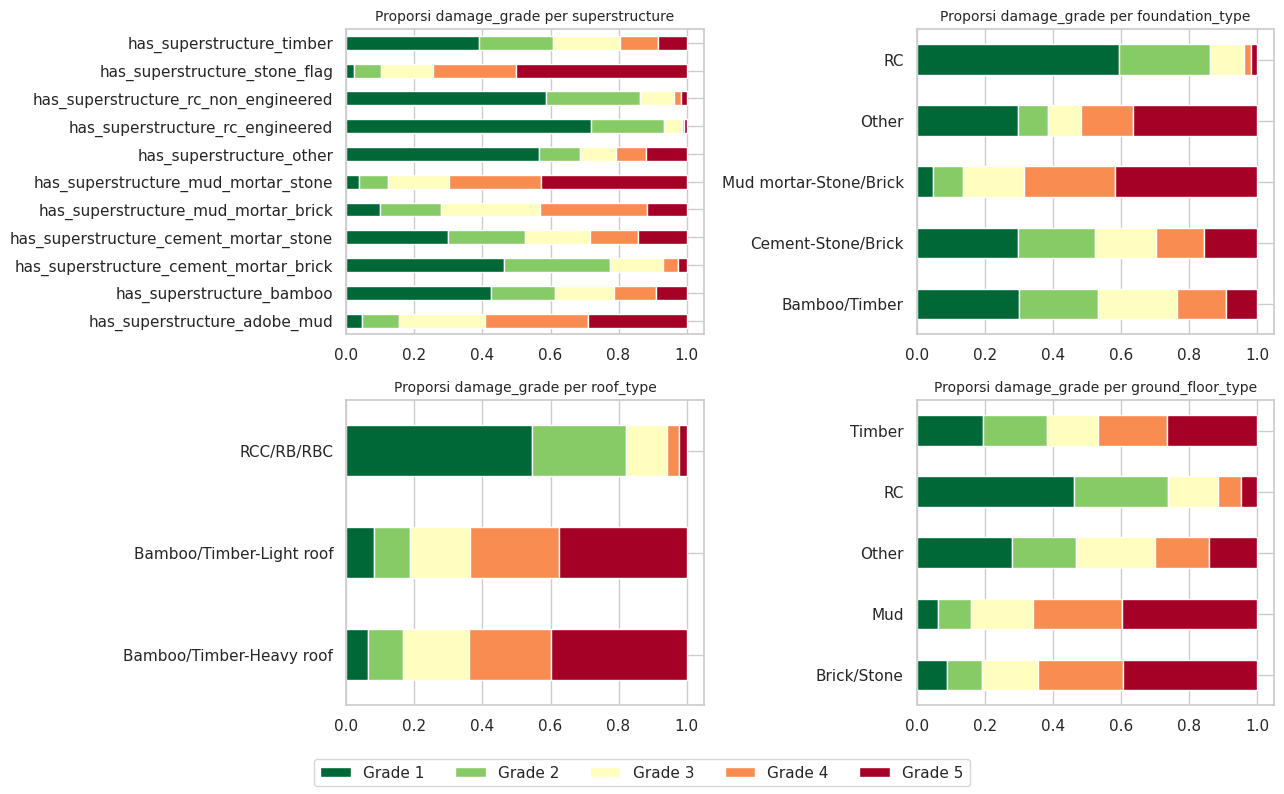

In [7]:
cats = ["superstructure", "foundation_type", "roof_type", "ground_floor_type"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cats):
    ct = pd.crosstab(train[c], train[TARGET], normalize="index")[order]
    ct = ct.loc[sorted(ct.index)]
    ct.plot(kind="barh", stacked=True, ax=ax, colormap="RdYlGn_r", legend=False)
    ax.set_title(f"Proporsi damage_grade per {c}", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIG_DIR / "damage_by_category.png", dpi=150)
plt.show()

## 5. Faktor wilayah (geografis)

Jumlah wilayah unik -> district: 11 | vdcmun: 110 | ward: 945
Ward di test yang tidak ada di train: 0 baris


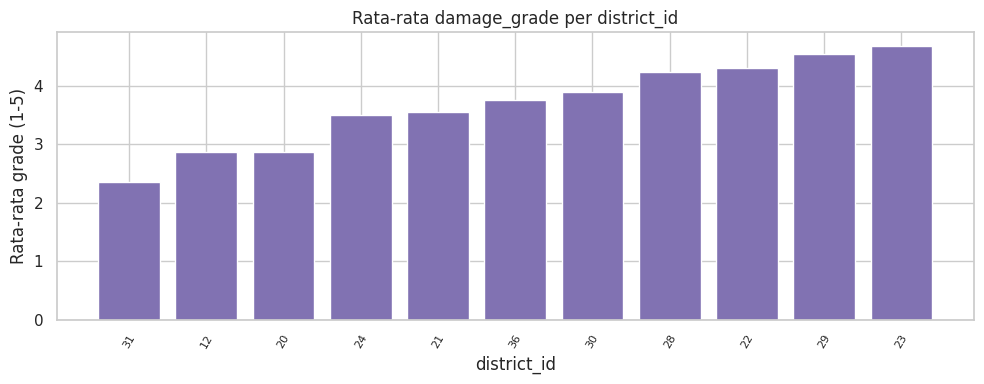

In [8]:
print("Jumlah wilayah unik -> district:", train.district_id.nunique(),
      "| vdcmun:", train.vdcmun_id.nunique(), "| ward:", train.ward_id.nunique())
print("Ward di test yang tidak ada di train:", (~test.ward_id.isin(train.ward_id)).sum(), "baris")

dist = d.groupby("district_id")["grade_num"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dist.index.astype(str), dist["mean"], color="#8172B2")
ax.set(title="Rata-rata damage_grade per district_id", xlabel="district_id", ylabel="Rata-rata grade (1-5)")
plt.setp(ax.get_xticklabels(), rotation=60, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "damage_by_district.png", dpi=150)
plt.show()

## 6. Noise pada label

Apakah bangunan dengan fitur yang **persis sama** selalu punya `damage_grade` yang sama? Kalau tidak, ada batas atas performa yang tidak bisa dilewati model apa pun.

In [9]:
feat = [c for c in train.columns if c not in (ID_COL, TARGET)]
dup = train.duplicated(subset=feat, keep=False)
print(f"Baris yang profil fiturnya identik dengan baris lain: {dup.mean():.1%}")
g = train[dup].groupby(feat, observed=True)[TARGET].agg(["nunique", "size"])
print(f"Dari {len(g):,} kelompok fitur identik, {(g['nunique'] > 1).mean():.1%} punya label yang BERBEDA-BEDA")

Baris yang profil fiturnya identik dengan baris lain: 10.6%
Dari 22,620 kelompok fitur identik, 47.3% punya label yang BERBEDA-BEDA


## Kesimpulan EDA

- Tidak ada missing value; satu-satunya kode khusus adalah `age_building = 999` (umur tidak diketahui) yang proporsinya kecil dan sama di train maupun test.
- Distribusi kelas tidak seimbang -> perlu `class_weight='balanced'`
- Jenis material/struktur bangunan, jumlah lantai, dan wilayah tampak berhubungan dengan tingkat kerusakan.
- Banyak bangunan dengan fitur identik memiliki label berbeda -> data berisik, sehingga skor model akan mentok di kisaran tertentu.